# Lab #2

The purpose of this laboratory is to put NumPy, pandas and Matplotlib to work on two datasets.
More specifically, you will learn how to:
- load and explore a dataset with pandas, and look at it with Matplotlib;
- move from a pandas DataFrame to NumPy arrays;
- implement your first Machine Learning model, the K-Nearest Neighbors (KNN) classifier, with NumPy, and measure its accuracy;
- (optionally) extend it with inheritance, the way scikit-learn models share one interface;
- explore a larger real-world dataset, the Points of Interest of New York City, with pandas and Matplotlib.

## 0 Setup
### 0.1 Kernel and libraries
This is the first lab you run on your own machine. Open this notebook in VS Code and select, with the kernel picker at the top right, the virtual environment you created for the course (`.venv`).

Then run the cell below: it should print the three versions without errors. If `import numpy` fails, the notebook is almost certainly running on the wrong kernel.

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("NumPy", np.__version__)
print("pandas", pd.__version__)
print("Matplotlib", matplotlib.__version__)

NumPy 2.5.3
pandas 3.0.6
Matplotlib 3.11.2


### 0.2 The datasets
In this laboratory you will use two datasets:
- **Iris**, which you already met in Lab 1: 150 flowers, each described by 4 measurements in cm (sepal length, sepal width, petal length, petal width) and by its species (Iris-setosa, Iris-versicolor or Iris-virginica). It is a CSV file without a header, available [here](https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data).
- **New York Points of Interest (POIs)**, a [zip file](https://github.com/dbdmg/data-science-lab/raw/master/datasets/NYC_POIs.zip) with three files:
    - `pois_all_info`: the list of the POIs of New York City, in TSV (Tab-Separated Values) format, i.e. a CSV file whose fields are separated by a TAB character instead of a comma;
    - `ny_municipality_pois_id.csv`: the `@id` of the POIs inside the New York City municipality, one per line;
    - `New_York_City_Map.PNG`: a map of the New York City municipality.

The fields of `pois_all_info` are:
- **@id**: the identifier of the POI;
- **@type**: the kind of OpenStreetMap element (`node`, `way` or `relation`);
- **@lat**, **@lon**: the latitude and longitude of the POI, in decimal degrees;
- **amenity**, **shop**, **public_transport**, **highway**: the four POI categories. When a POI belongs to a category, the corresponding field holds its type (e.g. `amenity` = `restaurant`), otherwise it is empty;
- **name**: the name of the POI, if any.

The cell below downloads both datasets in the folder of this notebook, unless they are already there.

In [2]:
import urllib.request
import zipfile
from pathlib import Path

IRIS_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"
POIS_URL = "https://github.com/dbdmg/data-science-lab/raw/master/datasets/NYC_POIs.zip"

if not Path("iris.csv").exists():
    urllib.request.urlretrieve(IRIS_URL, "iris.csv")

if not Path("pois_all_info").exists():
    urllib.request.urlretrieve(POIS_URL, "NYC_POIs.zip")
    with zipfile.ZipFile("NYC_POIs.zip") as archive:
        for name in archive.namelist():
            if not name.startswith("__MACOSX"):  # skip the macOS metadata stored in the archive
                archive.extract(name)

for name in ["iris.csv", "pois_all_info", "ny_municipality_pois_id.csv", "New_York_City_Map.PNG"]:
    print(f"{name}: {Path(name).stat().st_size} bytes")

iris.csv: 4551 bytes
pois_all_info: 4787894 bytes
ny_municipality_pois_id.csv: 581601 bytes
New_York_City_Map.PNG: 87105 bytes


## Exercises
Note that exercises marked with a (*) are optional, you should focus on completing the other ones first.

## 1 Iris: from exploration to a classifier
In Lab 1 you loaded Iris as a list of lists and computed its statistics with loops. Here you do the same with pandas, look at the data with Matplotlib, and then build a classifier with NumPy.

### 1.1 Load the dataset
Load `iris.csv` into a DataFrame `iris_df` whose columns are named `sepal_length`, `sepal_width`, `petal_length`, `petal_width` and `class` (see the `header` and `names` parameters of `pd.read_csv`).

*Check*: the shape of `iris_df` is `(150, 5)`, and its first row is `5.1, 3.5, 1.4, 0.2, Iris-setosa`.

In [3]:
FEATURES = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

iris_df = pd.read_csv("iris.csv", header=None, names=FEATURES + ["class"])
print(iris_df.shape)
iris_df.head()

(150, 5)


,sepal_length,sepal_width,petal_length,petal_width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


### 1.2 Statistics per species
Compute the mean and the standard deviation of the 4 measurements for each species, with a single pandas expression.

Compare the result with Exercise 3 of Lab 1: the means are the same, the standard deviations are not. Why? How do you get the values of Lab 1 back?

In [4]:
iris_df.groupby("class").agg(["mean", "std"])

sepal_length           sepal_width           petal_length  \
                        mean       std        mean       std         mean   
class                                                                       
Iris-setosa            5.006  0.352490       3.418  0.381024        1.464   
Iris-versicolor        5.936  0.516171       2.770  0.313798        4.260   
Iris-virginica         6.588  0.635880       2.974  0.322497        5.552   

                          petal_width            
                      std        mean       std  
class                                            
Iris-setosa      0.173511       0.244  0.107210  
Iris-versicolor  0.469911       1.326  0.197753  
Iris-virginica   0.551895       2.026  0.274650

In [5]:
# the standard deviation of Lab 1, which divides by n
iris_df.groupby("class").std(ddof=0)

,sepal_length,sepal_width,petal_length,petal_width
class,,,,
Iris-setosa,0.348947,0.377195,0.171767,0.106132
Iris-versicolor,0.510983,0.310644,0.465188,0.195765
Iris-virginica,0.629489,0.319255,0.546348,0.271890


**pandas computes the *sample* standard deviation, which divides by $n-1$ (`ddof=1` by default), while the formula of Lab 1 divides by $n$. With 50 flowers per species the two differ by a factor $\sqrt{50/49} \approx 1.01$. `std(ddof=0)` gives back the values of Lab 1 (NumPy's `np.std`, instead, uses `ddof=0` by default).**

### 1.3 Distribution of the features
In one figure, draw a box plot of each of the 4 features, with the feature names on the x axis (`tick_labels` parameter of `boxplot`) and the unit on the y axis.

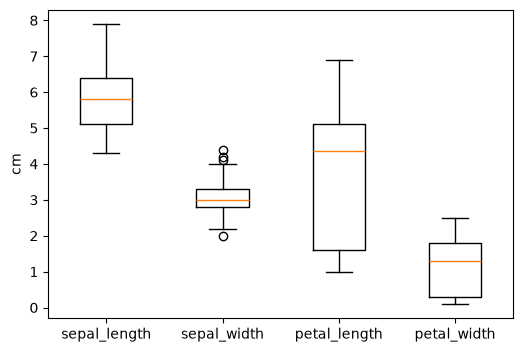

In [6]:
# tick_labels needs Matplotlib >= 3.9: older versions call this parameter labels
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([iris_df[feature] for feature in FEATURES], tick_labels=FEATURES)
ax.set_ylabel("cm")
plt.show()

### 1.4 Distribution of the features per species
Draw the box plots of Exercise 1.3 for each species separately, as three plots side by side in the same figure, each with the species as title. The three plots must use the same y scale, otherwise they cannot be compared (see the `sharey` parameter of `plt.subplots`).

Which features would you use to tell the three species apart?

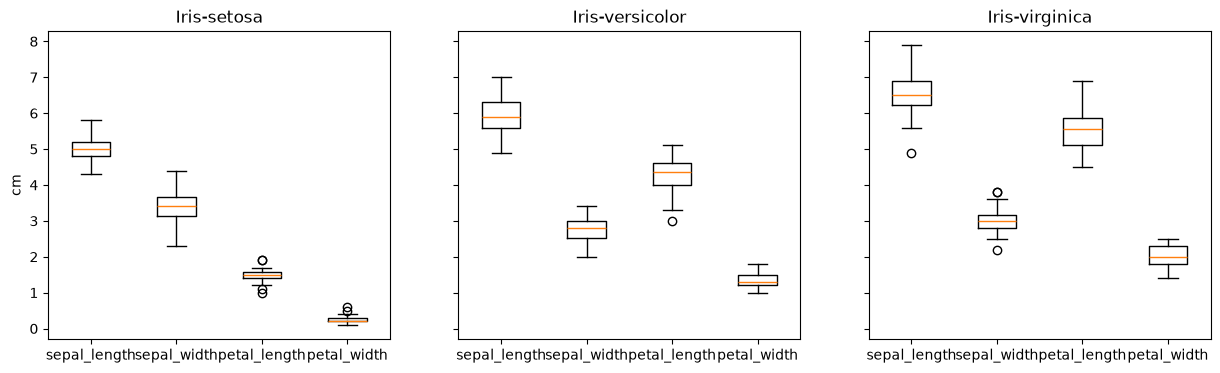

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (species, species_df) in zip(axes, iris_df.groupby("class")):
    ax.boxplot([species_df[feature] for feature in FEATURES], tick_labels=FEATURES)
    ax.set_title(species)
axes[0].set_ylabel("cm")
plt.show()

**The petal length and the petal width: their boxes are far apart for the three species, and in particular Iris-setosa has much smaller petals than the other two. The sepal measurements, instead, overlap a lot from one species to another.**

### 1.5 Pairs of features
A box plot shows one feature at a time. Now look at two features at a time: in one figure, draw a scatter plot for every pair of features (how many pairs are there?), with each species in its own color, a legend, and the feature names on the axes. `itertools.combinations` generates the pairs.

Does the figure confirm your answer to Exercise 1.4?

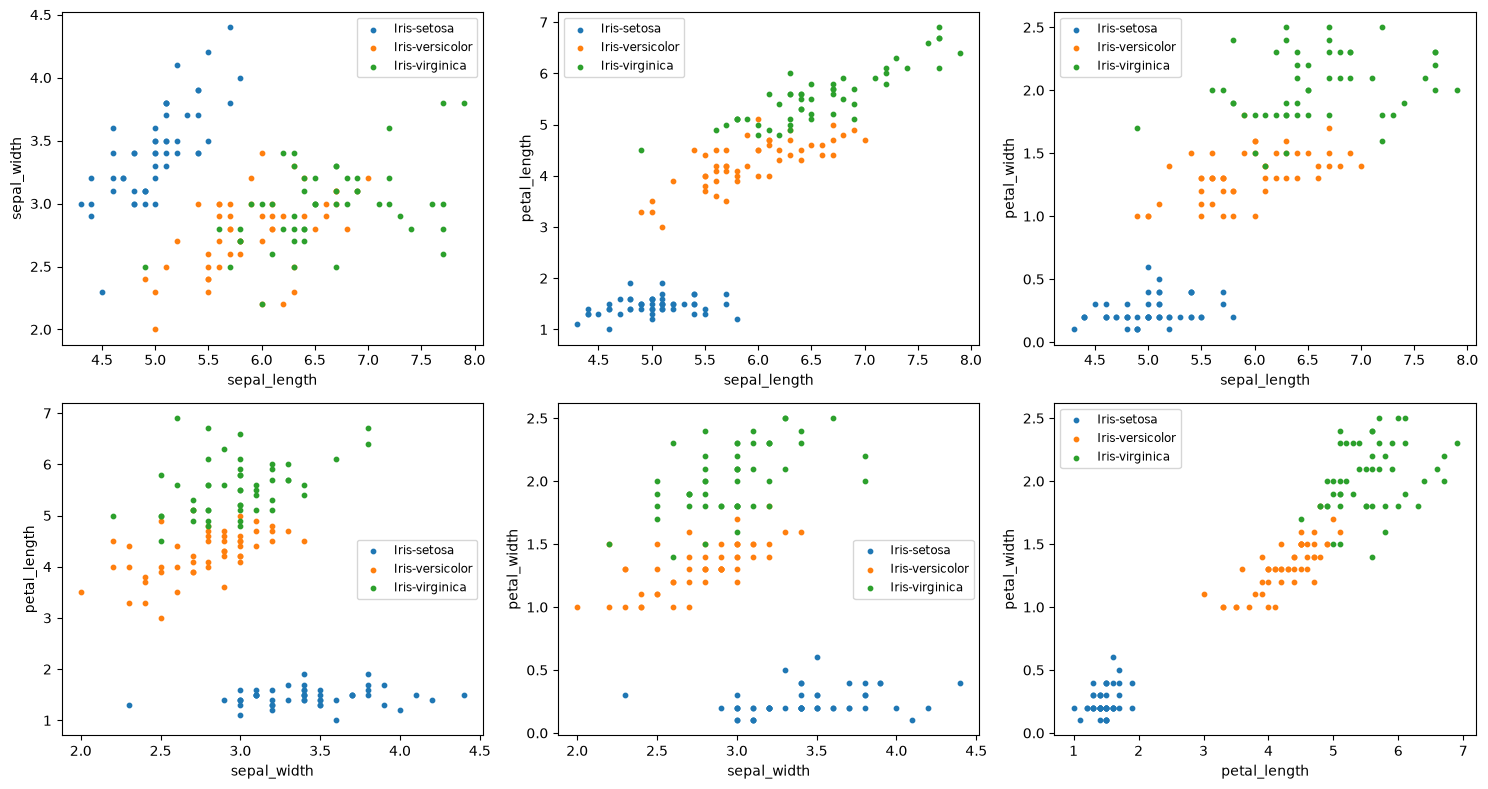

In [8]:
from itertools import combinations

fig, axes = plt.subplots(2, 3, figsize=(15, 8))  # C(4, 2) = 6 pairs
for ax, (feature_x, feature_y) in zip(axes.flat, combinations(FEATURES, 2)):
    for species, species_df in iris_df.groupby("class"):
        ax.scatter(species_df[feature_x], species_df[feature_y], s=10, label=species)
    ax.set_xlabel(feature_x)
    ax.set_ylabel(feature_y)
    ax.legend(fontsize="small")
fig.tight_layout()
plt.show()

**Yes: in the plot of petal length against petal width the three species form three almost separate groups, with only a small overlap between Iris-versicolor and Iris-virginica. Iris-setosa is far from the other two in every plot that involves a petal measurement.**

### 1.6 From pandas to NumPy
The classifier you are going to write works on NumPy arrays. Build:
- `X`, the 4 measurements, an array of shape `(150, 4)`;
- `y`, the species as integers, an array of shape `(150,)`, with this mapping:
    - Iris-setosa: 0
    - Iris-versicolor: 1
    - Iris-virginica: 2

*Check*: `X` has a float `dtype`, `y` an integer one, and `y` contains 50 zeros, 50 ones and 50 twos.

In [9]:
SPECIES = ["Iris-setosa", "Iris-versicolor", "Iris-virginica"]

X = iris_df[FEATURES].to_numpy()
y = iris_df["class"].map({species: label for label, species in enumerate(SPECIES)}).to_numpy()
print("X:", X.shape, X.dtype)
print("y:", y.shape, y.dtype, np.bincount(y))

X: (150, 4) float64
y: (150,) int64 [50 50 50]


### The K-Nearest Neighbors algorithm
In the rest of this part you will implement your own version of the K-Nearest Neighbors (KNN) algorithm, and use it to assign a species (i.e. a label) to flowers whose species is unknown.

The KNN algorithm is straightforward. Suppose that the measurements (e.g. the Iris features) and the label (e.g. the Iris species) of a set of samples are known in advance.

<img src="https://mlarchive.com/wp-content/uploads/2022/09/img2.png" width="800">

Then, whenever we want to label a new sample, we look at the K most similar samples (a.k.a. neighbors) and assign a label accordingly.

<img src="https://mlarchive.com/wp-content/uploads/2022/09/img1-1.png" width="800">

The simplest solution is a majority voting scheme: the new sample gets the label shared by most of its neighbors.
This approach is naive only at first sight: as the plots of Exercise 1.5 show, flowers of the same species do have similar measurements.
KNN is rarely the best model, but it is a valid baseline for many tasks.

### 1.7 Nearest neighbors of a sample
Define a function `k_nearest_neighbors(x, X, k)` that returns the indices of the `k` rows of `X` closest to the sample `x`, using the euclidean distance. Do not loop over the rows of `X`. (`np.linalg.norm` computes the norm of vectors.)

Apply it to the 36th sample (`X[35]`) with `k=5`, and print the indices and the labels of its neighbors.
- Which species would you guess for this sample?
- One of the neighbors is a bit special: which one, and why?

In [10]:
def k_nearest_neighbors(x, X, k):
    distances = np.linalg.norm(X - x, axis=1)  # x is subtracted from every row of X by broadcasting
    return np.argsort(distances)[:k]


neighbors = k_nearest_neighbors(X[35], X, k=5)
print("Indices of the 5 nearest neighbors:", neighbors)
print("Labels of the 5 nearest neighbors:", y[neighbors])
print("Label of the 36th sample:", y[35])

Indices of the 5 nearest neighbors: [35 49  1  2 40]
Labels of the 5 nearest neighbors: [0 0 0 0 0]
Label of the 36th sample: 0


**All 5 neighbors are Iris-setosa (label 0), so we would guess Iris-setosa, which is correct. The first neighbor is the sample itself (index 35, at distance 0): `X` contains the sample we are trying to classify. This is fine to test the function, but a classifier must never be evaluated on the data it already knows, which is why the next exercise splits the dataset.**

### 1.8 Training set and test set
To measure how good a classifier is, it has to be tested on samples it has never seen. Split the dataset at random:
- 20% of the samples form the **test set**: their features in `X_test`, their labels in `y_test`;
- the remaining 80% form the **training set**, `X_train` and `y_train`: this is the knowledge the model will use to make its predictions.

Each sample must end up in exactly one of the two sets, and the split must be the same at every run. (`np.random.default_rng(seed)` creates a random generator with a fixed seed; look at its `permutation` method.)

*Check*: the shapes are `(30, 4)` and `(30,)` for the test set, `(120, 4)` and `(120,)` for the training set.

Why would the first 30 rows of the file make a bad test set?

In [11]:
rng = np.random.default_rng(seed=0)
indices = rng.permutation(len(X))  # 0, ..., 149 in random order, each exactly once
n_test = len(X) * 20 // 100

X_test, y_test = X[indices[:n_test]], y[indices[:n_test]]
X_train, y_train = X[indices[n_test:]], y[indices[n_test:]]

print("X_test:", X_test.shape, "y_test:", y_test.shape)
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("Test samples per species:", np.bincount(y_test))

X_test: (30, 4) y_test: (30,)
X_train: (120, 4) y_train: (120,)
Test samples per species: [ 5 13 12]


**The file is sorted by species, so its first 30 rows are all Iris-setosa: the model would be tested on one species only (the easiest one), and its training set would have only 20 Iris-setosa against 50 of each of the other two.**

### 1.9 KNN as a class
From the next labs you will use the `scikit-learn` library, whose models share the same object-oriented interface: a `fit` method that learns from the training data and a `predict` method that labels new samples. Implement KNN with this interface, starting from the skeleton below (you are free to add other methods).
- `__init__` stores the number of neighbors `k`.
- `fit` stores the training data: KNN does not really learn anything, the model *is* the training set.
- `predict` labels each row of `X` with the label that is most frequent among its `k` nearest neighbors in the training set (majority voting). Reuse `k_nearest_neighbors`; `np.unique` can count how many times each value appears (see its `return_counts` parameter).
- (*) Compute the distances between all the rows of `X` and all the training samples at once, without looping over `X`. What shape must the array of differences have?

In [12]:
class KNearestNeighbors:
    def __init__(self, k):
        """
        Store the value of k in an attribute of the class and initialize other attributes.
        :param k: int, number of neighbors to consider.
        """
        self.k = k
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        """
        Store the 'prior knowledge' of your model, that will be used to predict new labels.
        :param X: input data points, ndarray, shape = (R, C).
        :param y: input labels, ndarray, shape = (R,).
        """
        self.X_train = X
        self.y_train = y

    def predict(self, X):
        """
        Run the KNN classification on X.
        :param X: input data points, ndarray, shape = (N, C).
        :return: labels, ndarray, shape = (N,).
        """
        if self.X_train is None:
            raise RuntimeError("call fit() before predict()")
        predictions = []
        for x in X:
            neighbors = k_nearest_neighbors(x, self.X_train, self.k)
            labels, counts = np.unique(self.y_train[neighbors], return_counts=True)
            predictions.append(labels[np.argmax(counts)])  # majority voting
        return np.array(predictions)

In [13]:
# (*) all the distances at once, by broadcasting
class KNearestNeighborsBroadcast(KNearestNeighbors):
    def predict(self, X):
        if self.X_train is None:
            raise RuntimeError("call fit() before predict()")
        # (N, 1, C) - (R, C) -> (N, R, C): the difference between each row of X and each training sample
        distances = np.linalg.norm(X[:, np.newaxis, :] - self.X_train, axis=2)  # (N, R)
        neighbors = np.argsort(distances, axis=1)[:, : self.k]  # (N, k), one row of indices per sample
        neighbor_labels = self.y_train[neighbors]  # (N, k)
        predictions = []
        for labels_of_x in neighbor_labels:  # the voting still goes row by row
            labels, counts = np.unique(labels_of_x, return_counts=True)
            predictions.append(labels[np.argmax(counts)])
        return np.array(predictions)

### 1.10 Accuracy
Create a model with `k=3`, fit it on the training set, and predict the species of the test set into an array `y_pred`. Then compute the **accuracy** of the model, the fraction of test samples whose species has been guessed correctly:

$$ \text{accuracy} = {\text{number of correct predictions} \over \text{total number of predictions}} $$

*Check*: on Iris, the accuracy of KNN is usually 0.9 or more (guessing at random would give about 0.33).

In [14]:
knn = KNearestNeighbors(k=3)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

print("Predicted labels:", y_pred)
print("True labels:     ", y_test)
print("Accuracy:", (y_pred == y_test).mean())  # the mean of a boolean array is the fraction of True

Predicted labels: [1 2 1 2 2 1 1 2 1 0 1 2 2 1 0 1 1 0 0 2 1 1 1 1 2 0 2 2 1 2]
True labels:      [1 2 1 2 2 1 1 2 2 0 1 1 2 1 0 1 1 0 0 2 2 1 1 1 2 0 2 2 1 2]
Accuracy: 0.9


In [15]:
# (*) the broadcast version gives the same predictions
knn_broadcast = KNearestNeighborsBroadcast(k=3)
knn_broadcast.fit(X_train, y_train)
print("Same predictions:", (knn_broadcast.predict(X_test) == y_pred).all())

Same predictions: True


### 1.11 Where are the mistakes?
The accuracy is a single number; a plot shows where the mistakes are. Using the two petal features, draw in one figure:
- the training samples, colored by species;
- the test samples on top of them, with a different marker and colored by *predicted* species;
- the misclassified test samples, highlighted so that they stand out (e.g. circled: see the `facecolors` and `edgecolors` parameters of `scatter`).

Where do the misclassified samples lie?

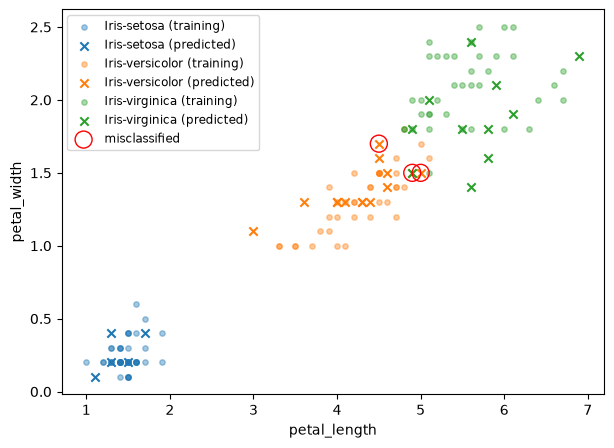

In [16]:
fig, ax = plt.subplots(figsize=(7, 5))
for label, species in enumerate(SPECIES):
    train = X_train[y_train == label]
    ax.scatter(train[:, 2], train[:, 3], s=15, alpha=0.4, color=f"C{label}", label=f"{species} (training)")
    test = X_test[y_pred == label]
    ax.scatter(test[:, 2], test[:, 3], marker="x", color=f"C{label}", label=f"{species} (predicted)")

wrong = X_test[y_pred != y_test]
ax.scatter(wrong[:, 2], wrong[:, 3], s=150, facecolors="none", edgecolors="red", label="misclassified")
ax.set_xlabel("petal_length")
ax.set_ylabel("petal_width")
ax.legend(fontsize="small")
plt.show()

**The mistakes are between Iris-versicolor and Iris-virginica, where the two species overlap: there, the closest training samples of a flower may belong to the other species. Iris-setosa, far from the other two, is always classified correctly.**

### Inheritance in a nutshell
A class can be defined as an extension of another one: `class Child(Parent)` **inherits** all the attributes and methods of `Parent`, and can add new ones or **override** (redefine) existing ones. Run the example below.
- `Square` and `Circle` inherit `describe` from `Shape`, and override `area`.
- `super()` gives access to the methods of the parent class, even those the child has overridden. It has two typical uses:
    - in the constructor, `super().__init__(...)` runs the constructor of the parent, so that the attributes it sets (here `self.name`) exist in the child too. A child that defines its own `__init__` *replaces* the one of the parent: without this call, those attributes are never set;
    - in any other method, `super().method(...)` *extends* the version of the parent instead of rewriting it: `Square.describe` calls `Shape.describe` and adds the side.
- `describe` is written once, in `Shape`, but calls `self.area()`: Python runs the `area` of the class the object actually belongs to. The loop treats the three objects in the same way, and each behaves in its own way: this is called **polymorphism**.

*Note*: a method whose name starts with two underscores (e.g. `__area`) is renamed by Python to `_Shape__area` inside `Shape` and to `_Square__area` inside `Square`, so a child class cannot override it. Methods meant to be overridden must not start with `__`, unless they also end with `__`, like `__init__`: these special methods are never renamed.

In [17]:
import math


class Shape:
    def __init__(self, name):
        self.name = name

    def area(self):
        return 0.0

    def describe(self):
        return f"{self.name} with area {self.area():.2f}"


class Square(Shape):
    def __init__(self, side):
        super().__init__("square")  # runs Shape.__init__, which sets self.name
        self.side = side

    def area(self):  # overrides Shape.area
        return self.side**2

    def describe(self):  # extends Shape.describe
        return super().describe() + f" (side {self.side})"


class Circle(Shape):
    def __init__(self, radius):
        super().__init__("circle")
        self.radius = radius

    def area(self):
        return math.pi * self.radius**2


for shape in [Shape("point"), Square(3), Circle(1)]:
    print(shape.describe())

point with area 0.00
square with area 9.00 (side 3)
circle with area 3.14


### 1.12 (*) Other distances
Your KNN uses the euclidean distance, but other distances may work better on other data, e.g.:
- the Minkowski distance of order $p$: $ minkowski_p(a, b) = \left(\sum_{i=1}^n |a_i - b_i|^p\right)^{1/p} $, which is the Manhattan distance for $p = 1$ and the euclidean one for $p = 2$;
- the cosine distance: $ cosine(a, b) = 1 - \frac{\sum_{i=1}^n a_i b_i}{ \sqrt{\sum_{i=1}^n a_i^2} \cdot \sqrt{\sum_{i=1}^n b_i^2}} $

Add them through inheritance, without copying the KNN algorithm:
1. Rewrite `KNearestNeighbors` so that the distance is computed by a method of its own, `distances(self, x)`, which returns the euclidean distances between `x` and each training sample, and that `predict` uses.
2. Define `MinkowskiKNN(k, p)`, which inherits from `KNearestNeighbors`, takes the order `p` as an extra constructor parameter, and overrides `distances`. Its constructor must still store `k` and initialize the training data: do it without repeating the code of the parent.
3. Define `CosineKNN(k)`, which overrides `distances`. The norms of the training samples do not change from one prediction to the next: compute them once, in `fit`, by extending the `fit` of the parent rather than rewriting it.
4. With a single loop over `KNearestNeighbors(k=3)`, `MinkowskiKNN(k=3, p=1)`, `MinkowskiKNN(k=3, p=3)` and `CosineKNN(k=3)`, fit each model on the training set and print its accuracy on the test set.

What happens if `MinkowskiKNN.__init__` does not call `super().__init__`? Which part of the code is polymorphic?

In [18]:
class KNearestNeighbors:
    def __init__(self, k):
        self.k = k
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y

    def distances(self, x):
        """Euclidean distance between x and each training sample, shape = (R,)."""
        return np.linalg.norm(self.X_train - x, axis=1)

    def predict(self, X):
        if self.X_train is None:
            raise RuntimeError("call fit() before predict()")
        predictions = []
        for x in X:
            neighbors = np.argsort(self.distances(x))[: self.k]  # whichever distances() the object has
            labels, counts = np.unique(self.y_train[neighbors], return_counts=True)
            predictions.append(labels[np.argmax(counts)])
        return np.array(predictions)


class MinkowskiKNN(KNearestNeighbors):
    def __init__(self, k, p):
        super().__init__(k)  # the parent stores k and initializes the training data
        self.p = p

    def distances(self, x):
        return (np.abs(self.X_train - x) ** self.p).sum(axis=1) ** (1 / self.p)


class CosineKNN(KNearestNeighbors):
    def fit(self, X, y):
        super().fit(X, y)  # store the training data as the parent does...
        self.train_norms = np.linalg.norm(X, axis=1)  # ...and compute their norms once, not at every prediction

    def distances(self, x):
        dot = (self.X_train * x).sum(axis=1)
        return 1 - dot / (self.train_norms * np.linalg.norm(x))


models = {
    "euclidean": KNearestNeighbors(k=3),
    "Minkowski, p=1 (Manhattan)": MinkowskiKNN(k=3, p=1),
    "Minkowski, p=3": MinkowskiKNN(k=3, p=3),
    "cosine": CosineKNN(k=3),
}
for name, model in models.items():
    model.fit(X_train, y_train)  # the same calls for every model
    accuracy = (model.predict(X_test) == y_test).mean()
    print(f"{name}: accuracy {accuracy:.2f}")

euclidean: accuracy 0.90
Minkowski, p=1 (Manhattan): accuracy 0.90
Minkowski, p=3: accuracy 0.90
cosine: accuracy 0.97


In [19]:
# without super().__init__(k), the constructor of the parent never runs
class BrokenMinkowskiKNN(MinkowskiKNN):
    def __init__(self, k, p):
        self.p = p  # self.k is never set


broken = BrokenMinkowskiKNN(k=3, p=1)
broken.fit(X_train, y_train)  # fit sets X_train and y_train, so this works...
try:
    broken.predict(X_test)  # ...but predict needs self.k
except AttributeError as error:
    print("AttributeError:", error)

AttributeError: 'BrokenMinkowskiKNN' object has no attribute 'k'


**Without `super().__init__(k)`, the constructor of `MinkowskiKNN` replaces the one of `KNearestNeighbors` instead of extending it: `self.k` is never set, and `predict` fails with an `AttributeError` (see the cell above). The same holds for `CosineKNN.fit`: without `super().fit(X, y)` the training data would never be stored.**

**The call `self.distances(x)` inside `predict` is polymorphic: it is written once, in `KNearestNeighbors`, and runs the euclidean, Minkowski or cosine version depending on the class of the object. So is the loop over the models, which calls `fit` and `predict` on each without knowing which one it is. This is the same reason why all scikit-learn models have `fit` and `predict`: code written for one model works with any other.**

#

---
## 2 New York Points of Interest
Iris is small and clean. The POIs dataset is larger, has many empty fields and needs some work before it can be analyzed: a typical situation with real-world data.

### 2.1 Load the dataset
Load `pois_all_info` into a DataFrame `all_pois_df`, with the `@id` column as index (see the `index_col` parameter of `pd.read_csv`). Remember that it is a TSV file.

*Check*: `all_pois_df` has 77884 rows.

pandas probably warns you that some columns have mixed types. Look at the data: why does it happen? Find in the documentation of `pd.read_csv` how to avoid it.

In [20]:
TEXT_COLUMNS = ["amenity", "name", "shop", "public_transport", "highway"]

# declaring the types of the text columns removes the "mixed types" warning
# (low_memory=False also works: it makes pandas infer the types on the whole file at once)
all_pois_df = pd.read_csv("pois_all_info", sep="\t", index_col="@id", dtype={column: "str" for column in TEXT_COLUMNS})
print(all_pois_df.shape)
all_pois_df.head()

(77884, 8)


,@type,@lat,@lon,amenity,name,shop,public_transport,highway
@id,,,,,,,,
42432939,node,40.814104,-73.949623,NaN,NaN,NaN,stop_position,NaN
42448838,node,40.761647,-73.949864,NaN,NaN,NaN,stop_position,NaN
42723103,node,40.852182,-73.772677,ferry_terminal,Hart Island Ferry Terminal,NaN,NaN,NaN
42764076,node,40.867164,-73.882158,NaN,Botanical Garden,NaN,stop_position,NaN
42811266,node,40.704806,-73.772734,NaN,NaN,NaN,stop_position,NaN


**pandas infers the type of each column from its values. With the default `low_memory=True`, the parser reads a large file in chunks and infers the types chunk by chunk, to keep its memory low while parsing (the resulting DataFrame is the same size either way). The category columns and `name` are empty in most rows, so in some chunks a column contains only `NaN`, which is a float, and in others it contains text: the inferred types disagree, and pandas warns.**

**The clean fix is to tell pandas the types instead of letting it guess: `dtype={"amenity": "str", ...}` for the five text columns. The types are then deterministic, and the fix keeps working on files too large to parse in one go. `low_memory=False` also removes the warning, by inferring the types on the whole file at once: on a 4.6 MB file like this one it costs nothing, but it is the memory optimization that gets switched off.**

### 2.2 POIs on the map
Write a function `draw_map(ax)` that draws the map of New York City on the axes `ax`: load the image with `plt.imread("New_York_City_Map.PNG")` and show it with `ax.imshow(img, extent=[-74.258, -73.7, 40.49, 40.92])`. The `extent` maps the pixels of the image to longitude (x) and latitude (y), so that the POIs land in the right place. A few POIs lie outside the map: keep the axes within its borders.

Then draw the map and all the POIs on it, small enough not to hide the map.

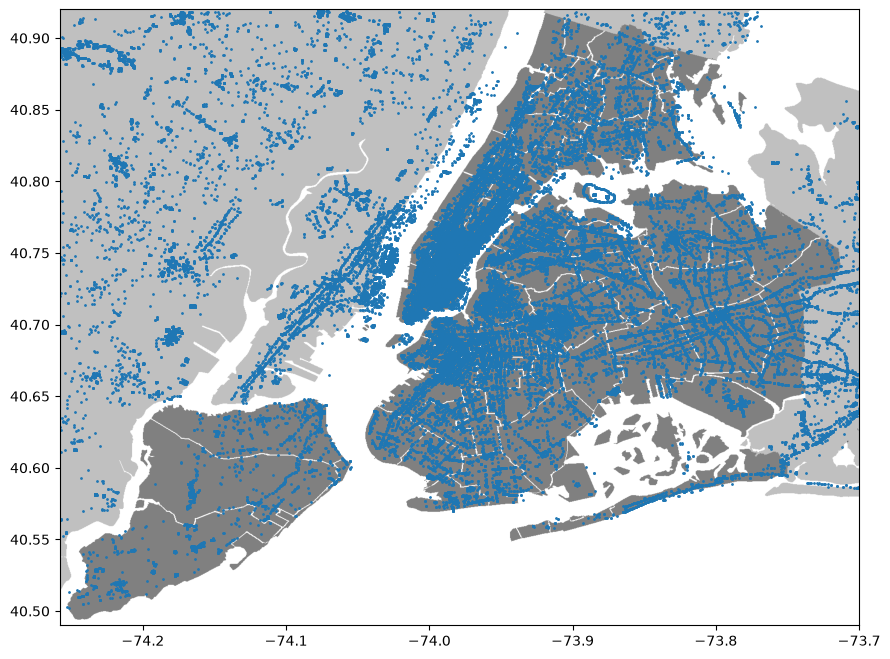

In [21]:
MAP_EXTENT = [-74.258, -73.7, 40.49, 40.92]  # longitude from, to; latitude from, to


def draw_map(ax):
    img = plt.imread("New_York_City_Map.PNG")
    ax.imshow(img, extent=MAP_EXTENT)
    ax.set_xlim(MAP_EXTENT[:2])  # otherwise the POIs outside the map widen the axes
    ax.set_ylim(MAP_EXTENT[2:])


fig, ax = plt.subplots(figsize=(12, 8))
draw_map(ax)
ax.scatter(all_pois_df["@lon"], all_pois_df["@lat"], s=1)  # POIs without coordinates are skipped
plt.show()

### 2.3 POIs of the New York City municipality
Many POIs lie outside the municipality. Keep in a DataFrame `pois_df` only the POIs whose `@id` is listed in `ny_municipality_pois_id.csv` (a file without a header), and plot them on the map. (`Index.isin` may help.)

*Check*: `pois_df` has 53521 rows. If you get more, find out why.

53521 of 77884 POIs are in the municipality


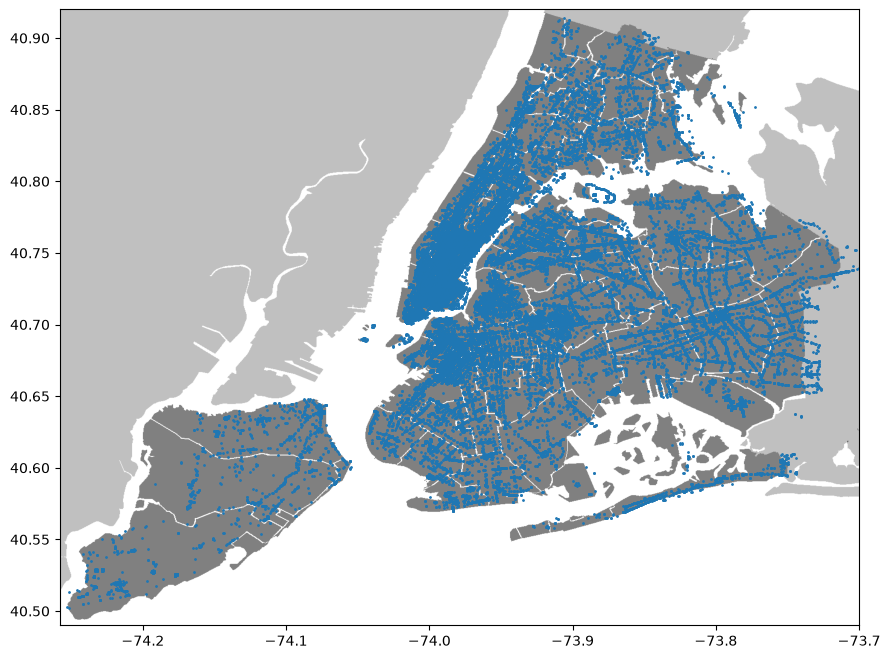

In [22]:
ny_ids = pd.read_csv("ny_municipality_pois_id.csv", header=None, names=["@id"])
# a boolean mask keeps each row at most once. all_pois_df.loc[ny_ids["@id"]] would return 53550 rows
# instead: some ids are repeated in the list, and .loc returns the matching rows once per occurrence.
# (Some ids label two rows of pois_all_info itself: 6 of them are in pois_df, and the mask keeps both rows.)
pois_df = all_pois_df[all_pois_df.index.isin(ny_ids["@id"])]
print(f"{len(pois_df)} of {len(all_pois_df)} POIs are in the municipality")

fig, ax = plt.subplots(figsize=(12, 8))
draw_map(ax)
ax.scatter(pois_df["@lon"], pois_df["@lat"], s=1)
plt.show()

### 2.4 A category column
Add to `pois_df` a column `category` holding the category of each POI (`amenity`, `shop`, `public_transport` or `highway`), i.e. the name of the category field that is not empty; leave it empty for the POIs without a category. Then print how many POIs fall in each category, the empty one included (see `value_counts` and its `dropna` parameter).

How many POIs have more than one category? Which category does your code assign them, and why?

In [23]:
CATEGORIES = ["amenity", "shop", "public_transport", "highway"]

# with pandas 2.x this line raises a SettingWithCopyWarning, because pois_df is a slice of all_pois_df:
# add .copy() to the end of its definition in Exercise 2.3. pandas >= 3.0 (Copy-on-Write) does not warn
pois_df["category"] = None
# some POIs have a value in more than one category field: the loop only fills the POIs
# without a category yet, so they keep the first of their categories in the order of CATEGORIES
for category in CATEGORIES:  # try: CATEGORIES[::-1]
    pois_df.loc[pois_df["category"].isna() & pois_df[category].notna(), "category"] = category

print("POIs with more than one category:", (pois_df[CATEGORIES].notna().sum(axis=1) > 1).sum())
pois_df["category"].value_counts(dropna=False)

POIs with more than one category: 6021


category
amenity             24697
None                10194
shop                 8571
public_transport     8359
highway              1700
Name: count, dtype: int64

**6021 POIs have more than one category, mostly bus stops, which are both `public_transport` and `highway` POIs. The code above keeps the first of their categories in the order `amenity`, `shop`, `public_transport`, `highway`, because it only assigns a category to the POIs that do not have one yet. Any order is acceptable, as long as it is a deliberate choice: four independent assignments, one per category, would let the last one silently overwrite the others.**

### 2.5 POIs per category
Draw the number of POIs of each category as a bar chart, with a title and a label on the y axis.

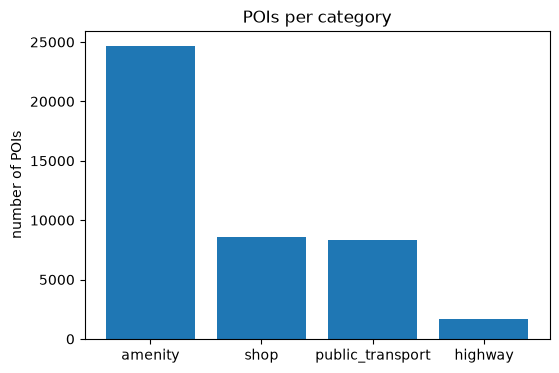

In [24]:
category_counts = pois_df["category"].value_counts()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(category_counts.index, category_counts.to_numpy())
ax.set_title("POIs per category")
ax.set_ylabel("number of POIs")
plt.show()

### 2.6 Most frequent amenity types
Show the 10 most frequent amenity types (the values of the `amenity` column), with their number of POIs, from the most to the least frequent.

In [25]:
amenity_counts = pois_df["amenity"].value_counts()  # already sorted, most frequent first
amenity_counts.head(10)

amenity
bicycle_parking     6052
restaurant          4156
fast_food           1531
cafe                1374
post_box            1093
bench               1064
place_of_worship    1012
school               912
drinking_water       862
bar                  821
Name: count, dtype: int64

In [26]:
# the same with groupby
pois_df.groupby("amenity").size().sort_values(ascending=False).head(10)

amenity
bicycle_parking     6052
restaurant          4156
fast_food           1531
cafe                1374
post_box            1093
bench               1064
place_of_worship    1012
school               912
drinking_water       862
bar                  821
dtype: int64

### 2.7 The top 5 amenity types on the map
Plot on the map the POIs of the 5 most frequent amenity types, each type in its own color, with a legend. (The points are small: see the `markerscale` parameter of `legend`.)

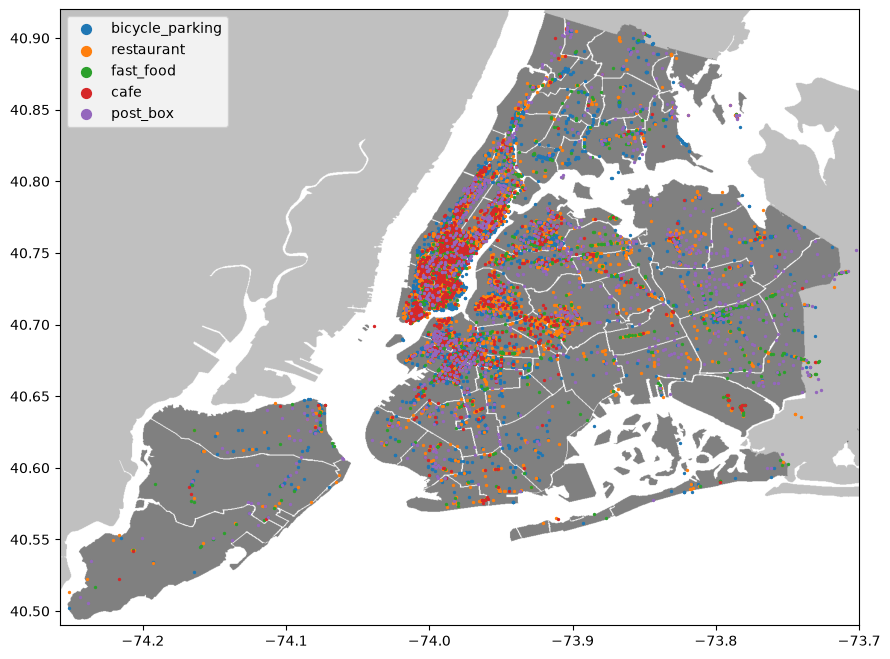

In [27]:
fig, ax = plt.subplots(figsize=(12, 8))
draw_map(ax)
for amenity in amenity_counts.index[:5]:
    amenity_df = pois_df[pois_df["amenity"] == amenity]
    ax.scatter(amenity_df["@lon"], amenity_df["@lat"], s=2, label=amenity)
ax.legend(markerscale=5)
plt.show()

### 2.8 (*) The top 5 types of each category
For each of the 4 categories, draw a bar chart of the 5 most frequent types among the POIs of that category, as assigned in Exercise 2.4 (e.g. the 5 most frequent `shop` types among the `shop` POIs), as four plots side by side in one figure, each with the category as title. The type names are long: keep them from overlapping (see `tick_params`).

How many bars does `highway` have with the order you chose in Exercise 2.4, and why?

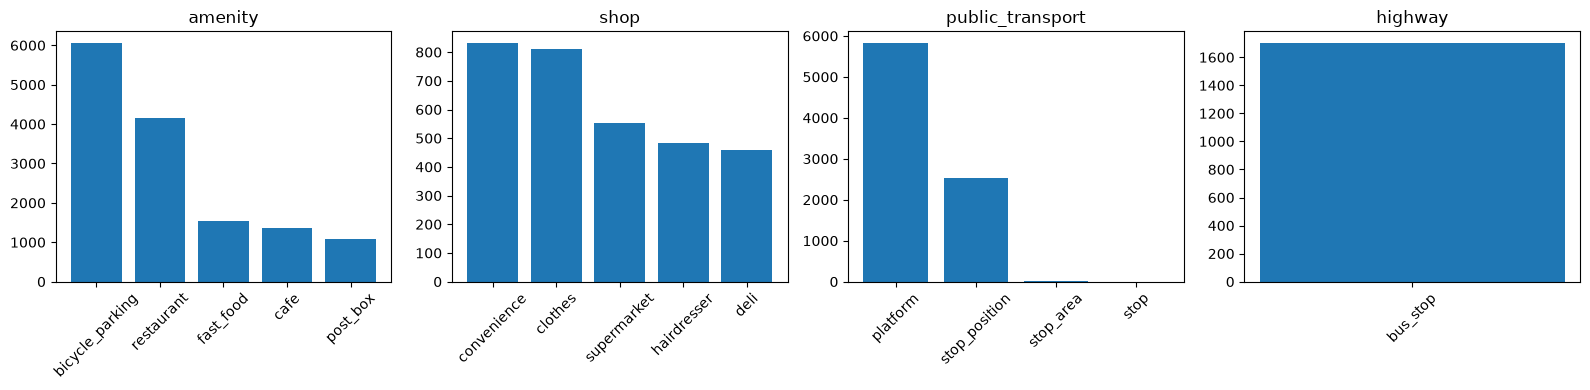

In [28]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, category in zip(axes, CATEGORIES):
    # the POIs of this category, not every POI whose `category` field is filled: they are the ones counted in 2.5
    type_counts = pois_df.loc[pois_df["category"] == category, category].value_counts().head(5)
    ax.bar(type_counts.index, type_counts.to_numpy())
    ax.set_title(category)
    ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
plt.show()

**With the order chosen in Exercise 2.4, `highway` has a single bar: a POI is a `highway` POI only if it has no other category, and the 1700 POIs left are all bus stops: the other bus stops are also tagged as `public_transport` POIs, and are counted there. Counting the whole `highway` column instead would show about 7500 bus stops, which contradicts the bar chart of Exercise 2.5.**

**The answer depends on the order: with `highway` before `public_transport`, the bus stops are counted as `highway` POIs (about 7500), and a second bar appears for the only `crossing`, which is also a `public_transport` POI.**